# QCNN+SVM & QCNN+QSVM — multi-seed runs 


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import random
import zipfile, os

# -------------------------------
BASE_MBR_DIR = "./data/mbrset"
EXTRACT_DIR = "./data/mbrset_images"

os.makedirs(EXTRACT_DIR, exist_ok=True)

zip_list = [
    "training_mbrset.zip",
    "testing_mbrset.zip"
]

# ============================================================
# EXTRACT IMAGES
# ============================================================

for zname in zip_list:

    zpath = os.path.join(
        BASE_MBR_DIR,
        zname
    )

    print(f"Extracting: {zname}")

    with zipfile.ZipFile(zpath, "r") as z:
        z.extractall(EXTRACT_DIR)

print("All images extracted into:", EXTRACT_DIR)

# ============================================================
# LOAD LABELS
# ============================================================

CSV_PATH = os.path.join(
    BASE_MBR_DIR,
    "labels_mbrset.csv"
)

df = pd.read_csv(CSV_PATH)

print("Labels loaded:")

# Clean final_edema column safely
df["final_edema"] = (
    df["final_edema"]
    .replace(["Yes", "YES", "yes"], 1)
    .replace(["No", "NO", "no"], 0)
)

# Force invalid values to real NaN
df["final_edema"] = pd.to_numeric(df["final_edema"], errors="coerce")

# Drop invalid / missing labels
df = df.dropna(subset=["final_edema"])

# Convert to int
df["final_edema"] = df["final_edema"].astype(int)

print(df["final_edema"].value_counts())


def normalize_image_name(name):
    name = str(name).strip()
    if not name.lower().endswith((".jpg", ".jpeg", ".png")):
        name += ".jpg"
    return name.lower()

df["file"] = df["file"].apply(normalize_image_name)

import pathlib

image_dict = {
    p.name.lower(): str(p)
    for p in pathlib.Path(EXTRACT_DIR).rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("Total images found:", len(image_dict))

df["path"] = df["file"].map(image_dict)
df = df.dropna(subset=["path"])

x_all = df["path"].tolist()
y_all = df["final_edema"].tolist()

print(" Usable samples:", len(x_all))

from sklearn.model_selection import StratifiedShuffleSplit
import numpy as np

from sklearn.model_selection import StratifiedShuffleSplit

# ============================================================
# 70% Train, 30% Temp
# ============================================================
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)

for train_idx, temp_idx in sss1.split(x_all, y_all):
    x_train = [x_all[i] for i in train_idx]
    y_train = [y_all[i] for i in train_idx]
    x_temp  = [x_all[i] for i in temp_idx]
    y_temp  = [y_all[i] for i in temp_idx]

# ============================================================
# Split temp (30%) → 10% Val, 20% Test
# That means: test_size = 20/30 = 0.6667
# ============================================================
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=2/3, random_state=42)

for val_idx, test_idx in sss2.split(x_temp, y_temp):
    x_val  = [x_temp[i] for i in val_idx]
    y_val  = [y_temp[i] for i in val_idx]
    x_test = [x_temp[i] for i in test_idx]
    y_test = [y_temp[i] for i in test_idx]

print(" Final split:")
print("Train:", len(x_train))  # ~70%
print("Val:  ", len(x_val))    # ~10%
print("Test: ", len(x_test))   # ~20%


print("\nLabel distribution:")
print("Train:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Val:  ", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test: ", dict(zip(*np.unique(y_test, return_counts=True))))

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

cw = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weights)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
num_classes = 2   # binary edema (0/1)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
])

def load_and_preprocess(path, label, augment=False):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)

    if augment:
        img = data_augmentation(img)

    img = preprocess_input(img)
    return img, tf.cast(label, tf.int32)

def make_dataset(paths, labels, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths))
    ds = ds.map(lambda x, y: load_and_preprocess(x, y, augment),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(x_train, y_train, augment=True, shuffle=True)
val_ds   = make_dataset(x_val,   y_val,   augment=False)
test_ds  = make_dataset(x_test,  y_test,  augment=False)



In [ ]:
train_set = set(x_train)
val_set   = set(x_val)
test_set  = set(x_test)

assert train_set.isdisjoint(val_set), " Train–Val overlap detected!"
assert train_set.isdisjoint(test_set), " Train–Test overlap detected!"
assert val_set.isdisjoint(test_set),   " Val–Test overlap detected!"

print(" Path-level check passed: no overlap between splits.")


In [ ]:
import hashlib
from tqdm import tqdm

def sha1(path, chunk_size=1 << 20):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

print(" Hashing images (this may take a few minutes)...")

train_hashes = {sha1(p) for p in tqdm(x_train)}
val_hashes   = {sha1(p) for p in tqdm(x_val)}
test_hashes  = {sha1(p) for p in tqdm(x_test)}

assert train_hashes.isdisjoint(val_hashes), " Train–Val content overlap!"
assert train_hashes.isdisjoint(test_hashes), " Train–Test content overlap!"
assert val_hashes.isdisjoint(test_hashes),   " Val–Test content overlap!"

print(" Content-level check passed: no duplicate images across splits.")


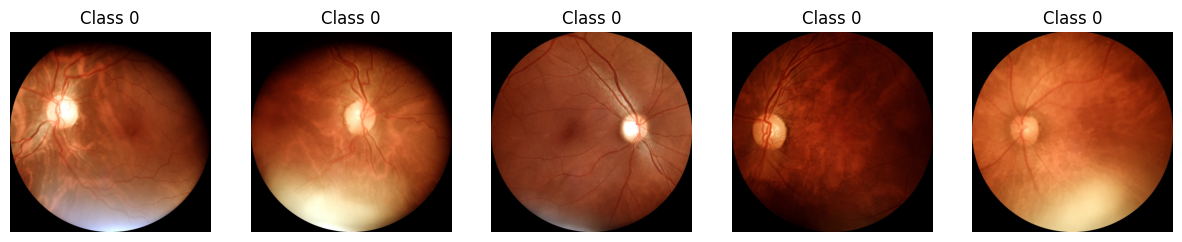

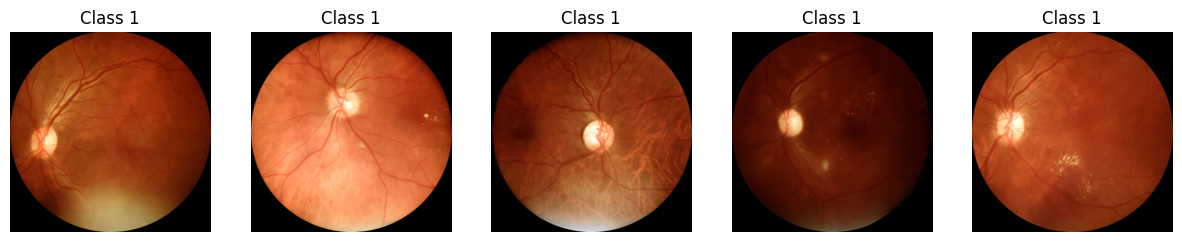

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

def show_examples_per_class(x_paths, y_labels, class_id, n=5):
    # Select paths for this class
    paths = [p for p, y in zip(x_paths, y_labels) if y == class_id]

    if len(paths) == 0:
        print(f"No images found for class {class_id}")
        return

    # Choose n random samples
    sample_paths = random.sample(paths, min(n, len(paths)))

    plt.figure(figsize=(15, 3))
    for i, p in enumerate(sample_paths):
        img = Image.open(p).convert("RGB")
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(f"Class {class_id}")
        plt.axis("off")
    plt.show()


#  Show samples for both classes (0 and 1)
for cls in [0, 1]:
    show_examples_per_class(x_train, y_train, class_id=cls, n=5)


In [ ]:
# !pip install -q pennylane pennylane-lightning tqdm


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# ============================================================
# SHARED SETUP — dataset loaders + HybridQCNN class definition
# (architecture identical to the original notebook; NOT trained here,
#  only used to load per-seed checkpoints for feature extraction)
# ============================================================
import numpy as np
from PIL import Image
from tqdm import tqdm
import gc

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import pennylane as qml
from pennylane.qnn import TorchLayer

from sklearn.metrics import accuracy_score, classification_report

IMG_SIZE = 224
BATCH_SIZE = 12

mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

test_transform = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.1)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

class ImagePathDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, int(self.labels[idx])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

_pin = torch.cuda.is_available()

# Feature-extraction loaders: no shuffle needed (order doesn't matter
# for fitting scaler/PCA/SVM), num_workers=0 to avoid Windows spawn hangs.
train_ds = ImagePathDataset(x_train, y_train, transform=test_transform)
val_ds   = ImagePathDataset(x_val,   y_val,   transform=test_transform)
test_ds  = ImagePathDataset(x_test,  y_test,  transform=test_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=_pin)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=_pin)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=_pin)

# ---- HybridQCNN architecture ----
backbone_template = models.resnet18(pretrained=True)
backbone_fc_dim = backbone_template.fc.in_features

n_qubits = 8
q_layers = 2


try:
    qdev = qml.device("lightning.qubit", wires=n_qubits)
except Exception:
    qdev = qml.device("default.qubit", wires=n_qubits)

def qcnn_circuit(inputs, weights):
    inputs = torch.flatten(inputs)
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)
    for l in range(q_layers):
        for i in range(n_qubits):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)
            qml.RZ(weights[l, i, 2], wires=i)
        for i in range(0, n_qubits - 1, 2):
            qml.CNOT(wires=[i, i + 1])
        for i in range(1, n_qubits - 1, 2):
            qml.CNOT(wires=[i, i + 1])
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (q_layers, n_qubits, 3)}
qnode = qml.QNode(qcnn_circuit, qdev, interface="torch", diff_method="adjoint")
qlayer_template = TorchLayer(qnode, weight_shapes)

# ============================================================
# HybridQCNN — inference-safe version
# ============================================================

class HybridQCNN(nn.Module):

    def __init__(self):

        super().__init__()

        bb = models.resnet18(
            pretrained=False
        )

        bb.fc = nn.Identity()

        self.backbone = bb

        self.reduce = nn.Linear(
            backbone_fc_dim,
            n_qubits
        )

        self.qlayer = TorchLayer(
            qnode,
            weight_shapes
        )

        self.classifier = nn.Sequential(
            nn.Linear(
                n_qubits,
                64
            ),
            nn.ReLU(),
            nn.Linear(
                64,
                1
            )
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Classical backbone
        # ----------------------------------------------------

        feats = self.backbone(x)

        angles = (
            torch.tanh(
                self.reduce(feats)
            )
            * (torch.pi / 2)
        )

        # ----------------------------------------------------
        # Quantum layer
        # ----------------------------------------------------
        

        q_outs = []

        for sample_angles in angles:

            q = self.qlayer(
                sample_angles.cpu()
            )

            q_outs.append(
                q.to(angles.device)
            )

        q_outs = torch.stack(
            q_outs
        )

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        return self.classifier(
            q_outs
        )

# ============================================================
# LOAD QCNN VALIDATION + TEST PROBABILITIES
# ============================================================

def get_qcnn_proba(model, loader):

    model.eval()

    all_probs = []

    with torch.no_grad():

        for imgs, labels in loader:

            imgs = imgs.to(
                device,
                non_blocking=True
            )

            logits = model(
                imgs
            ).squeeze(1)

            probs = torch.sigmoid(
                logits
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    return np.asarray(all_probs)


def load_qcnn_probs(seed):

    # --------------------------------------------------------
    # Load the trained QCNN checkpoint
    # --------------------------------------------------------

    ckpt_path = (
        f"best_qcnn_binary_seed_{seed}.pth"
    )

    model = HybridQCNN().to(device)

    model.load_state_dict(
        torch.load(
            ckpt_path,
            map_location=device
        )
    )

    model.eval()

    # --------------------------------------------------------
    # Validation probabilities
    # --------------------------------------------------------

    print(
        f"Extracting validation probabilities — Seed {seed}"
    )

    val_cnn_proba = get_qcnn_proba(
        model,
        val_loader
    )

    # --------------------------------------------------------
    # Test probabilities
    # --------------------------------------------------------

    print(
        f"Extracting test probabilities — Seed {seed}"
    )

    test_cnn_proba = get_qcnn_proba(
        model,
        test_loader
    )

    # --------------------------------------------------------
    # Free model
    # --------------------------------------------------------

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        val_cnn_proba,
        test_cnn_proba
    )

def extract_qcnn_features(model, loader):
    feats, labels = [], []
    model.eval()
    with torch.no_grad():
        for imgs, y in loader:
            imgs = imgs.to(device)
            cnn_feats = model.backbone(imgs)
            feats.append(cnn_feats.cpu().numpy())
            labels.extend(y.numpy())
    return np.vstack(feats), np.array(labels)

SEEDS = [42, 123, 456]
print("Ready. SEEDS =", SEEDS)


In [ ]:
# ============================================================
# SVM — 3 seeds ( QCNN feature extraction -> PCA -> SVM -> alpha-fused ensemble)
# For each seed: loads that seed's QCNN checkpoint + saved QCNN probs,
# extracts backbone features from THAT model, fits scaler/PCA/SVM fresh,
# tunes fusion alpha on val, evaluates on test.
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, confusion_matrix
from joblib import dump

svm_results = {}

for seed in SEEDS:
    print(f"\n{'='*70}\n SVM — SEED {seed}\n{'='*70}")

    torch.manual_seed(seed)
    np.random.seed(seed)

    # ---- load this seed's trained QCNN ----
    model = HybridQCNN().to(device)
    ckpt_path = f"best_qcnn_binary_seed_{seed}.pth"
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    
    test_cnn_proba = load_qcnn_probs(seed)
    val_cnn_proba, test_cnn_proba = load_qcnn_probs(seed)
    # ---- feature extraction (from THIS seed's backbone) ----
    print("Extracting QCNN features...")
    X_train, y_train_np = extract_qcnn_features(model, train_loader)
    X_val,   y_val_np   = extract_qcnn_features(model, val_loader)
    X_test,  y_test_np  = extract_qcnn_features(model, test_loader)

    # ---- scaler + PCA (unchanged) ----
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled   = scaler.transform(X_val)
    X_test_scaled  = scaler.transform(X_test)

    pca = PCA(n_components=0.95, svd_solver="full")
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_val_pca   = pca.transform(X_val_scaled)
    X_test_pca  = pca.transform(X_test_scaled)

    # ---- SVM grid search (unchanged, random_state=seed added only so
    #      the probability-calibration folds differ per seed) ----
    param_grid = {
        "C": [0.5, 1, 2, 5, 10],
        "gamma": ["scale", 0.01, 0.02, 0.05],
        "kernel": ["rbf"],
        "class_weight": ["balanced"]
    }

    svm = SVC(probability=True, random_state=seed)

    clf = GridSearchCV(svm, param_grid, cv=3, scoring="roc_auc", n_jobs=1, verbose=0)
    print("Training SVM...")
    clf.fit(X_train_pca, y_train_np)

    svm_best = clf.best_estimator_
    print("Best SVM params:", clf.best_params_)

    svm_val_prob  = svm_best.predict_proba(X_val_pca)[:, 1]
    svm_test_prob = svm_best.predict_proba(X_test_pca)[:, 1]

    # ---- alpha tuning on val ----
    alphas = np.linspace(0, 1, 41)
    best_alpha, best_auc = None, -1
    for a in alphas:
        fused_val = a * svm_val_prob + (1 - a) * val_cnn_proba
        auc = roc_auc_score(y_val_np, fused_val)
        if auc > best_auc:
            best_auc, best_alpha = auc, a

    fused_test = best_alpha * svm_test_prob + (1 - best_alpha) * test_cnn_proba
    final_pred = (fused_test >= 0.5).astype(int)

    print(f"Best alpha: {best_alpha:.2f} | Val AUC: {best_auc:.4f}")
    print(classification_report(y_test_np, final_pred, digits=4))

    dump({
        "svm": svm_best, "scaler": scaler, "pca": pca, "alpha": best_alpha
    }, f"qcnn_svm_ensemble_seed{seed}.joblib")

    svm_results[seed] = {
        "val_prob": fused_val if False else (best_alpha * svm_val_prob + (1 - best_alpha) * val_cnn_proba),
        "test_prob": fused_test,
        "y_val": y_val_np,
        "y_test": y_test_np,
        "best_alpha": best_alpha,
        "val_auc": best_auc
    }

    
    del model, X_train, X_val, X_test, X_train_scaled, X_val_scaled, X_test_scaled
    del X_train_pca, X_val_pca, X_test_pca, svm, clf
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nSVM done for all seeds:", list(svm_results.keys()))



 SVM — SEED 42
Extracting validation probabilities — Seed 42
Extracting test probabilities — Seed 42
Extracting validation probabilities — Seed 42
Extracting test probabilities — Seed 42
Extracting QCNN features...
Training SVM...
Best SVM params: {'C': 0.5, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}
Best alpha: 0.90 | Val AUC: 0.9443
              precision    recall  f1-score   support

           0     0.9569    0.9665    0.9616       895
           1     0.6053    0.5412    0.5714        85

    accuracy                         0.9296       980
   macro avg     0.7811    0.7538    0.7665       980
weighted avg     0.9264    0.9296    0.9278       980


 SVM — SEED 123


c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Extracting validation probabilities — Seed 123
Extracting test probabilities — Seed 123
Extracting validation probabilities — Seed 123
Extracting test probabilities — Seed 123
Extracting QCNN features...
Training SVM...
Best SVM params: {'C': 0.5, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}
Best alpha: 0.30 | Val AUC: 0.9418
              precision    recall  f1-score   support

           0     0.9617    0.9542    0.9579       895
           1     0.5543    0.6000    0.5763        85

    accuracy                         0.9235       980
   macro avg     0.7580    0.7771    0.7671       980
weighted avg     0.9264    0.9235    0.9248       980


 SVM — SEED 456


c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Extracting validation probabilities — Seed 456
Extracting test probabilities — Seed 456
Extracting validation probabilities — Seed 456
Extracting test probabilities — Seed 456
Extracting QCNN features...
Training SVM...
Best SVM params: {'C': 0.5, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}
Best alpha: 0.60 | Val AUC: 0.9572
              precision    recall  f1-score   support

           0     0.9659    0.9486    0.9572       895
           1     0.5446    0.6471    0.5914        85

    accuracy                         0.9224       980
   macro avg     0.7552    0.7978    0.7743       980
weighted avg     0.9293    0.9224    0.9254       980


SVM done for all seeds: [42, 123, 456]


In [ ]:
# ============================================================
# QSVM — shared feature extraction 
# The ResNet18 backbone is frozen/pretrained and the quantum feature map
# is deterministic (no seed dependence) — so this part is identical across
# seeds and only needs to run ONCE, not 3x. This is the main QSVM speedup.
# ============================================================
from collections import Counter
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from joblib import dump
import pennylane as qml

train_paths, train_labels = x_train, y_train
val_paths,   val_labels   = x_val,   y_val
test_paths,  test_labels  = x_test,  y_test

print("[QSVM] Train class counts:", dict(Counter(train_labels)))

# ---- frozen ResNet18 feature extractor (unchanged) ----
backbone_qsvm = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).to(device)
backbone_qsvm.eval()
feat_extractor = nn.Sequential(*list(backbone_qsvm.children())[:-1]).to(device)
for p in feat_extractor.parameters():
    p.requires_grad = False

def extract_features_qsvm(paths, labels, batch_size=64):
    ds = ImagePathDataset(paths, labels, test_transform)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=_pin)
    feats, ys = [], []
    with torch.no_grad():
        for imgs, y in dl:
            imgs = imgs.to(device)
            f = feat_extractor(imgs)
            f = torch.flatten(f, 1)
            feats.append(f.cpu().numpy())
            ys.extend(y.numpy().tolist())
    return np.vstack(feats), np.array(ys)

print("[QSVM] Extracting classical features (once, reused across seeds)...")
Xc_train, yc_train = extract_features_qsvm(train_paths, train_labels)
Xc_val,   yc_val   = extract_features_qsvm(val_paths,   val_labels)
Xc_test,  yc_test  = extract_features_qsvm(test_paths,  test_labels)

# ---- tiny quantum feature map (unchanged; switched to lightning.qubit for speed) ----
N_QUBITS = 8
try:
    qsvm_qdev = qml.device("lightning.qubit", wires=N_QUBITS)
except Exception:
    qsvm_qdev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(qsvm_qdev)
def quantum_feature_map(x):
    for i in range(N_QUBITS):
        qml.RY(x[i], wires=i)
    for i in range(N_QUBITS - 1):
        qml.CNOT(wires=[i, i+1])
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

def add_quantum_features(X, max_samples=500):
    Xq = X.copy()
    n = min(len(X), max_samples)
    q_feats = [quantum_feature_map(X[i][:N_QUBITS]) for i in tqdm(range(n), desc="QSVM features")]
    q_feats = np.array(q_feats)
    if len(X) > n:
        pad = np.zeros((len(X) - n, N_QUBITS))
        q_feats = np.vstack([q_feats, pad])
    return np.hstack([Xq, q_feats])

print("Adding quantum features (once, reused across seeds)...")
X_train_q = add_quantum_features(Xc_train)
X_val_q   = add_quantum_features(Xc_val)
X_test_q  = add_quantum_features(Xc_test)

print("Feature shapes:", X_train_q.shape, X_val_q.shape, X_test_q.shape)

del backbone_qsvm, feat_extractor
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


In [ ]:
# ============================================================
# QSVM — 3 seeds
# Only the CV split ordering and SVC's internal probability-calibration
# folds vary per seed (random_state=seed) — everything else identical.
# ============================================================
qsvm_results = {}

for seed in SEEDS:
    print(f"\n{'='*70}\n QSVM — SEED {seed}\n{'='*70}")

    val_cnn_proba, test_cnn_proba = load_qcnn_probs(seed)

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("power",  PowerTransformer(method="yeo-johnson", standardize=False)),
        ("pca",    PCA(svd_solver="full")),
        ("svc",    SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=seed))
    ])

    param_grid = {
        "pca__n_components": [0.90, 0.95, 0.98, 0.99],
        "svc__C":           [0.5, 1, 2, 5, 10],
        "svc__gamma":       [0.01, 0.02, 0.05, 0.1, "scale"]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    gs = GridSearchCV(pipe, param_grid, scoring="accuracy", cv=cv, n_jobs=1, verbose=0, refit=True)

    print("Training hybrid QSVM...")
    gs.fit(X_train_q, yc_train)

    best_qsvm = gs.best_estimator_
    print("Best params:", gs.best_params_)

    val_qsvm_proba  = best_qsvm.predict_proba(X_val_q)[:, 1]
    test_qsvm_proba = best_qsvm.predict_proba(X_test_q)[:, 1]

    print("VAL:")
    print(classification_report(yc_val, (val_qsvm_proba > 0.5).astype(int)))
    print("TEST:")
    print(classification_report(yc_test, (test_qsvm_proba > 0.5).astype(int)))

    
    alpha_q, qcnn_weight = 0.55, 0.45
    fused_val_q  = alpha_q * val_qsvm_proba  + qcnn_weight * val_cnn_proba
    fused_test_q = alpha_q * test_qsvm_proba + qcnn_weight * test_cnn_proba

    dump(best_qsvm, f"qcnn_qsvm_ensemble_seed{seed}.joblib")

    qsvm_results[seed] = {
        "val_prob": fused_val_q,
        "test_prob": fused_test_q,
        "y_val": yc_val,
        "y_test": yc_test
    }

    del gs, pipe
    gc.collect()

print("\nQSVM done for all seeds:", list(qsvm_results.keys()))



 QSVM — SEED 42


c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Extracting validation probabilities — Seed 42


Extracting test probabilities — Seed 42
Training hybrid QSVM...
Best params: {'pca__n_components': 0.99, 'svc__C': 10, 'svc__gamma': 'scale'}
VAL:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       447
           1       0.85      0.40      0.54        43

    accuracy                           0.94       490
   macro avg       0.90      0.69      0.75       490
weighted avg       0.94      0.94      0.93       490

TEST:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       895
           1       0.78      0.46      0.58        85

    accuracy                           0.94       980
   macro avg       0.87      0.72      0.77       980
weighted avg       0.94      0.94      0.93       980


 QSVM — SEED 123


c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Extracting validation probabilities — Seed 123
Extracting test probabilities — Seed 123
Training hybrid QSVM...
Best params: {'pca__n_components': 0.99, 'svc__C': 10, 'svc__gamma': 'scale'}
VAL:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       447
           1       0.85      0.40      0.54        43

    accuracy                           0.94       490
   macro avg       0.90      0.69      0.75       490
weighted avg       0.94      0.94      0.93       490

TEST:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       895
           1       0.78      0.45      0.57        85

    accuracy                           0.94       980
   macro avg       0.86      0.72      0.77       980
weighted avg       0.93      0.94      0.93       980


 QSVM — SEED 456


c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Parikshit\miniconda3\envs\ai_gpu\lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Extracting validation probabilities — Seed 456
Extracting test probabilities — Seed 456
Training hybrid QSVM...
Best params: {'pca__n_components': 0.98, 'svc__C': 5, 'svc__gamma': 'scale'}
VAL:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       447
           1       0.85      0.40      0.54        43

    accuracy                           0.94       490
   macro avg       0.90      0.69      0.75       490
weighted avg       0.94      0.94      0.93       490

TEST:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       895
           1       0.76      0.44      0.55        85

    accuracy                           0.94       980
   macro avg       0.85      0.71      0.76       980
weighted avg       0.93      0.94      0.93       980


QSVM done for all seeds: [42, 123, 456]



 QSVM + QCNN ENSEMBLE — SEED 42

VALIDATION CLASSIFICATION REPORT
--------------------------------------------------
              precision    recall  f1-score   support

     Class 0     0.9467    0.9933    0.9694       447
     Class 1     0.8571    0.4186    0.5625        43

    accuracy                         0.9429       490
   macro avg     0.9019    0.7059    0.7660       490
weighted avg     0.9388    0.9429    0.9337       490

VALIDATION CONFUSION MATRIX
[[444   3]
 [ 25  18]]


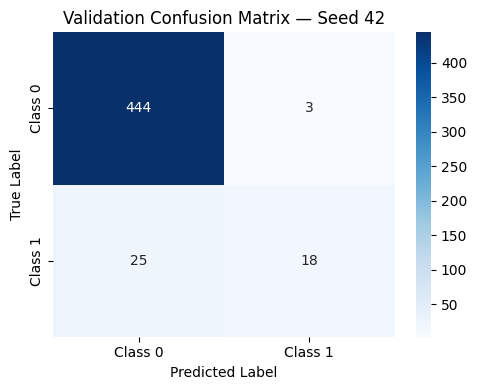


TEST CLASSIFICATION REPORT
--------------------------------------------------
              precision    recall  f1-score   support

     Class 0     0.9514    0.9844    0.9676       895
     Class 1     0.7407    0.4706    0.5755        85

    accuracy                         0.9398       980
   macro avg     0.8461    0.7275    0.7716       980
weighted avg     0.9331    0.9398    0.9336       980

TEST CONFUSION MATRIX
[[881  14]
 [ 45  40]]


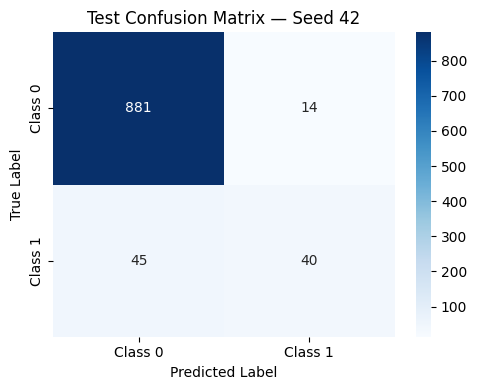


 QSVM + QCNN ENSEMBLE — SEED 123

VALIDATION CLASSIFICATION REPORT
--------------------------------------------------
              precision    recall  f1-score   support

     Class 0     0.9467    0.9933    0.9694       447
     Class 1     0.8571    0.4186    0.5625        43

    accuracy                         0.9429       490
   macro avg     0.9019    0.7059    0.7660       490
weighted avg     0.9388    0.9429    0.9337       490

VALIDATION CONFUSION MATRIX
[[444   3]
 [ 25  18]]


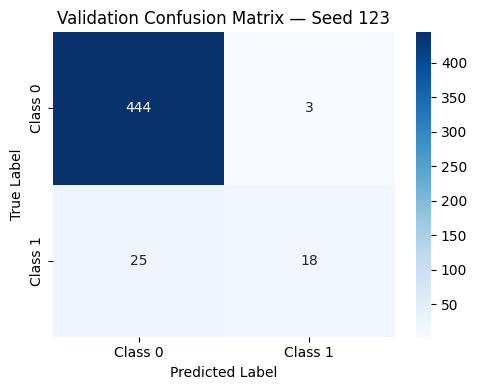


TEST CLASSIFICATION REPORT
--------------------------------------------------
              precision    recall  f1-score   support

     Class 0     0.9526    0.9877    0.9698       895
     Class 1     0.7885    0.4824    0.5985        85

    accuracy                         0.9439       980
   macro avg     0.8705    0.7350    0.7842       980
weighted avg     0.9384    0.9439    0.9376       980

TEST CONFUSION MATRIX
[[884  11]
 [ 44  41]]


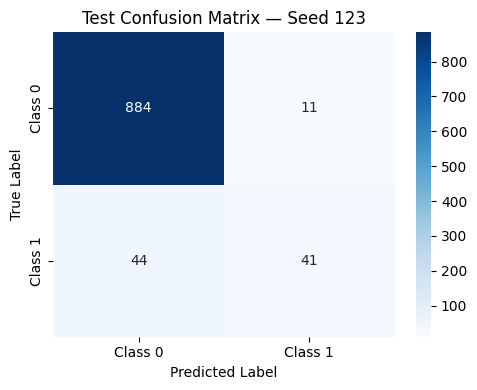


 QSVM + QCNN ENSEMBLE — SEED 456

VALIDATION CLASSIFICATION REPORT
--------------------------------------------------
              precision    recall  f1-score   support

     Class 0     0.9569    0.9933    0.9748       447
     Class 1     0.8846    0.5349    0.6667        43

    accuracy                         0.9531       490
   macro avg     0.9208    0.7641    0.8207       490
weighted avg     0.9506    0.9531    0.9477       490

VALIDATION CONFUSION MATRIX
[[444   3]
 [ 20  23]]


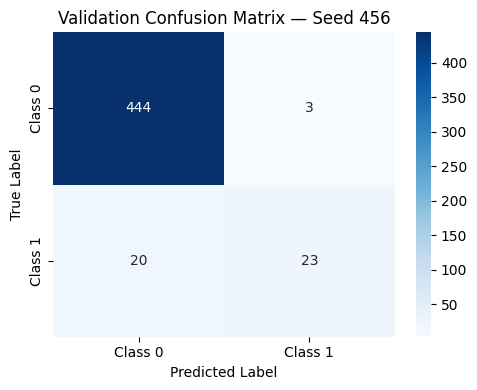


TEST CLASSIFICATION REPORT
--------------------------------------------------
              precision    recall  f1-score   support

     Class 0     0.9562    0.9765    0.9663       895
     Class 1     0.6818    0.5294    0.5960        85

    accuracy                         0.9378       980
   macro avg     0.8190    0.7530    0.7812       980
weighted avg     0.9324    0.9378    0.9342       980

TEST CONFUSION MATRIX
[[874  21]
 [ 40  45]]


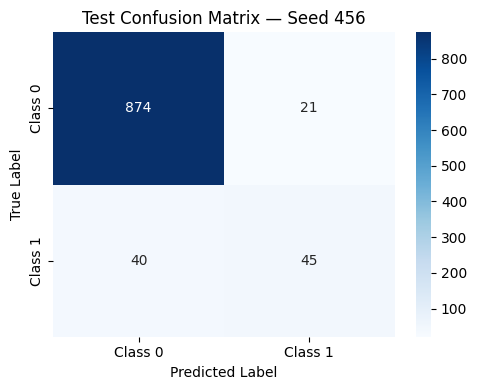

In [ ]:
# ============================================================
# INDIVIDUAL CONFUSION MATRICES + CLASSIFICATION REPORTS
# FOR EACH QSVM SEED
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

for seed in SEEDS:

    print("\n" + "=" * 70)
    print(f" QSVM + QCNN ENSEMBLE — SEED {seed}")
    print("=" * 70)

    results = qsvm_results[seed]

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    val_prob = results["val_prob"]
    y_val = results["y_val"]

    val_pred = (val_prob >= 0.5).astype(int)
    cm_val = confusion_matrix(y_val, val_pred)

    print("\nVALIDATION CLASSIFICATION REPORT")
    print("-" * 50)
    print(classification_report(
        y_val,
        val_pred,
        target_names=["Class 0", "Class 1"],
        digits=4
    ))

    print("VALIDATION CONFUSION MATRIX")
    print(cm_val)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm_val,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Class 0", "Class 1"],
        yticklabels=["Class 0", "Class 1"]
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Validation Confusion Matrix — Seed {seed}")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------
    test_prob = results["test_prob"]
    y_test = results["y_test"]

    test_pred = (test_prob >= 0.5).astype(int)
    cm_test = confusion_matrix(y_test, test_pred)

    print("\nTEST CLASSIFICATION REPORT")
    print("-" * 50)
    print(classification_report(
        y_test,
        test_pred,
        target_names=["Class 0", "Class 1"],
        digits=4
    ))

    print("TEST CONFUSION MATRIX")
    print(cm_test)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm_test,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Class 0", "Class 1"],
        yticklabels=["Class 0", "Class 1"]
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Test Confusion Matrix — Seed {seed}")
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# QSVM + QCNN ENSEMBLE — MEAN ± SD ACROSS 3 SEEDS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

seed_metrics = []

for seed in SEEDS:

    results = qsvm_results[seed]

    # ========================================================
    # VALIDATION
    # ========================================================
    y_val = results["y_val"]
    val_prob = results["val_prob"]
    val_pred = (val_prob >= 0.5).astype(int)

    val_cm = confusion_matrix(y_val, val_pred)

    val_metrics = {
        "Seed": seed,
        "Split": "Validation",
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, val_prob),
        "PR-AUC": average_precision_score(y_val, val_prob),
        "TN": val_cm[0, 0],
        "FP": val_cm[0, 1],
        "FN": val_cm[1, 0],
        "TP": val_cm[1, 1],
    }

    seed_metrics.append(val_metrics)

    # ========================================================
    # TEST
    # ========================================================
    y_test = results["y_test"]
    test_prob = results["test_prob"]
    test_pred = (test_prob >= 0.5).astype(int)

    test_cm = confusion_matrix(y_test, test_pred)

    test_metrics = {
        "Seed": seed,
        "Split": "Test",
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1": f1_score(y_test, test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_prob),
        "PR-AUC": average_precision_score(y_test, test_prob),
        "TN": test_cm[0, 0],
        "FP": test_cm[0, 1],
        "FN": test_cm[1, 0],
        "TP": test_cm[1, 1],
    }

    seed_metrics.append(test_metrics)


# ============================================================
# DATAFRAME — INDIVIDUAL SEED RESULTS
# ============================================================

metrics_df = pd.DataFrame(seed_metrics)

print("\n" + "=" * 90)
print("INDIVIDUAL SEED RESULTS")
print("=" * 90)

display(
    metrics_df[
        [
            "Seed", "Split",
            "Accuracy", "Precision", "Recall",
            "F1", "ROC-AUC", "PR-AUC",
            "TN", "FP", "FN", "TP"
        ]
    ].round(4)
)


# ============================================================
# MEAN ± SD
# ============================================================

metric_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

summary_rows = []

for split in ["Validation", "Test"]:

    split_df = metrics_df[metrics_df["Split"] == split]

    for metric in metric_cols:

        mean = split_df[metric].mean()
        sd = split_df[metric].std(ddof=1)

        summary_rows.append({
            "Split": split,
            "Metric": metric,
            "Mean": mean,
            "SD": sd,
            "Mean ± SD": f"{mean:.4f} ± {sd:.4f}"
        })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 90)
print("MEAN ± SD ACROSS 3 SEEDS")
print("=" * 90)

display(summary_df.round(4))


# ============================================================
# COMPACT TABLE FOR PAPER / REPORT
# ============================================================

paper_table = []

for split in ["Validation", "Test"]:

    split_df = metrics_df[metrics_df["Split"] == split]

    row = {"Split": split}

    for metric in metric_cols:

        mean = split_df[metric].mean()
        sd = split_df[metric].std(ddof=1)

        row[metric] = f"{mean:.4f} ± {sd:.4f}"

    paper_table.append(row)

paper_table_df = pd.DataFrame(paper_table)

print("\n" + "=" * 90)
print("PAPER-READY TABLE")
print("=" * 90)

display(paper_table_df)


INDIVIDUAL SEED RESULTS


,Seed,Split,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,42,Validation,0.9429,0.8571,0.4186,0.5625,0.8977,0.6801,444,3,25,18
1,42,Test,0.9398,0.7407,0.4706,0.5755,0.9035,0.6666,881,14,45,40
2,123,Validation,0.9429,0.8571,0.4186,0.5625,0.9318,0.7020,444,3,25,18
3,123,Test,0.9439,0.7885,0.4824,0.5985,0.9057,0.6611,884,11,44,41
4,456,Validation,0.9531,0.8846,0.5349,0.6667,0.9437,0.7457,444,3,20,23
5,456,Test,0.9378,0.6818,0.5294,0.5960,0.9122,0.6626,874,21,40,45



MEAN ± SD ACROSS 3 SEEDS


,Split,Metric,Mean,SD,Mean ± SD
0,Validation,Accuracy,0.9463,0.0059,0.9463 ± 0.0059
1,Validation,Precision,0.8663,0.0159,0.8663 ± 0.0159
2,Validation,Recall,0.4574,0.0671,0.4574 ± 0.0671
3,Validation,F1,0.5972,0.0601,0.5972 ± 0.0601
4,Validation,ROC-AUC,0.9244,0.0239,0.9244 ± 0.0239
5,Validation,PR-AUC,0.7092,0.0334,0.7092 ± 0.0334
6,Test,Accuracy,0.9405,0.0031,0.9405 ± 0.0031
7,Test,Precision,0.7370,0.0534,0.7370 ± 0.0534
8,Test,Recall,0.4941,0.0311,0.4941 ± 0.0311
9,Test,F1,0.5900,0.0126,0.5900 ± 0.0126



PAPER-READY TABLE


,Split,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Validation,0.9463 ± 0.0059,0.8663 ± 0.0159,0.4574 ± 0.0671,0.5972 ± 0.0601,0.9244 ± 0.0239,0.7092 ± 0.0334
1,Test,0.9405 ± 0.0031,0.7370 ± 0.0534,0.4941 ± 0.0311,0.5900 ± 0.0126,0.9071 ± 0.0045,0.6634 ± 0.0028


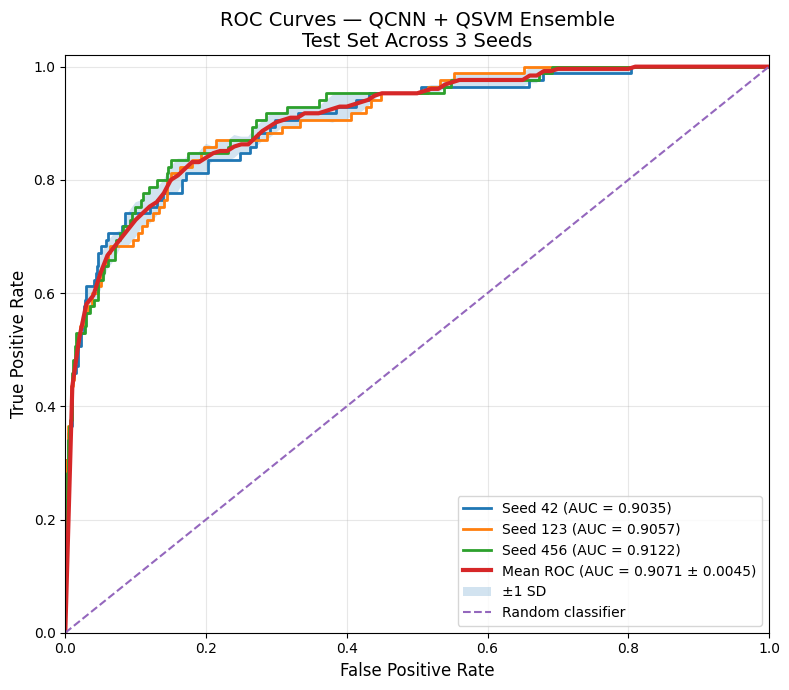


TEST ROC-AUC ACROSS 3 SEEDS
Seed 42: AUC = 0.9035
Seed 123: AUC = 0.9057
Seed 456: AUC = 0.9122
----------------------------------------------------------------------
Mean AUC : 0.9071
SD AUC   : 0.0045
Mean ± SD: 0.9071 ± 0.0045


In [ ]:
# ============================================================
# QSVM + QCNN ENSEMBLE — ROC CURVES FOR 3 SEEDS
# Individual curves + Mean ± SD ROC
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. ROC CURVES — TEST SET
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

mean_fpr = np.linspace(0, 1, 101)
tprs = []
aucs = []

for seed in SEEDS:

    results = qsvm_results[seed]

    y_test = results["y_test"]
    test_prob = results["test_prob"]

    # ROC
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    auc = roc_auc_score(y_test, test_prob)

    aucs.append(auc)

    # Interpolate TPR onto common FPR grid
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

    # Individual seed curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"Seed {seed} (AUC = {auc:.4f})"
    )


# ------------------------------------------------------------
# 2. MEAN ROC CURVE
# ------------------------------------------------------------

tprs = np.array(tprs)

mean_tpr = np.mean(tprs, axis=0)
std_tpr = np.std(tprs, axis=0, ddof=1)

mean_tpr[-1] = 1.0

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)

plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3,
    label=f"Mean ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})"
)


# ------------------------------------------------------------
# 3. ±1 SD REGION
# ------------------------------------------------------------

tpr_upper = np.minimum(mean_tpr + std_tpr, 1)
tpr_lower = np.maximum(mean_tpr - std_tpr, 0)

plt.fill_between(
    mean_fpr,
    tpr_lower,
    tpr_upper,
    alpha=0.2,
    label="±1 SD"
)


# ------------------------------------------------------------
# 4. RANDOM CLASSIFIER
# ------------------------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)


# ------------------------------------------------------------
# 5. FORMATTING
# ------------------------------------------------------------

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "ROC Curves — QCNN + QSVM Ensemble\n"
    "Test Set Across 3 Seeds",
    fontsize=14
)

plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.grid(alpha=0.3)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. PRINT AUC STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST ROC-AUC ACROSS 3 SEEDS")
print("=" * 70)

for seed, auc in zip(SEEDS, aucs):
    print(f"Seed {seed}: AUC = {auc:.4f}")

print("-" * 70)
print(f"Mean AUC : {mean_auc:.4f}")
print(f"SD AUC   : {std_auc:.4f}")
print(f"Mean ± SD: {mean_auc:.4f} ± {std_auc:.4f}")

In [ ]:
# ============================================================
# SAVE QCNN + QSVM PROBABILITIES — ALL 3 SEEDS
# ============================================================

import os
import numpy as np
import pandas as pd

save_dir = "qcnn_qsvm_probabilities"
os.makedirs(save_dir, exist_ok=True)

for seed in SEEDS:

    results = qsvm_results[seed]

    # --------------------------------------------------------
    # Validation probabilities
    # --------------------------------------------------------
    val_df = pd.DataFrame({
        "y_true": results["y_val"],
        "probability": results["val_prob"],
        "prediction": (results["val_prob"] >= 0.5).astype(int)
    })

    val_path = os.path.join(
        save_dir,
        f"qcnn_qsvm_seed{seed}_validation.csv"
    )

    val_df.to_csv(val_path, index=False)

    # --------------------------------------------------------
    # Test probabilities
    # --------------------------------------------------------
    test_df = pd.DataFrame({
        "y_true": results["y_test"],
        "probability": results["test_prob"],
        "prediction": (results["test_prob"] >= 0.5).astype(int)
    })

    test_path = os.path.join(
        save_dir,
        f"qcnn_qsvm_seed{seed}_test.csv"
    )

    test_df.to_csv(test_path, index=False)

    print(f"Seed {seed}:")
    print(f"  Validation → {val_path}")
    print(f"  Test       → {test_path}")

print("\nAll probabilities saved successfully.")

Seed 42:
  Validation → qcnn_qsvm_probabilities\qcnn_qsvm_seed42_validation.csv
  Test       → qcnn_qsvm_probabilities\qcnn_qsvm_seed42_test.csv
Seed 123:
  Validation → qcnn_qsvm_probabilities\qcnn_qsvm_seed123_validation.csv
  Test       → qcnn_qsvm_probabilities\qcnn_qsvm_seed123_test.csv
Seed 456:
  Validation → qcnn_qsvm_probabilities\qcnn_qsvm_seed456_validation.csv
  Test       → qcnn_qsvm_probabilities\qcnn_qsvm_seed456_test.csv

All probabilities saved successfully.


In [ ]:
# ============================================================
# SAVE QCNN + QSVM FUSED PROBABILITIES AS .NPZ
# ALL 3 SEEDS
# ============================================================

import os
import numpy as np

save_dir = "qcnn_qsvm_probabilities"
os.makedirs(save_dir, exist_ok=True)

for seed in SEEDS:

    results = qsvm_results[seed]

    np.savez(
        os.path.join(
            save_dir,
            f"qcnn_qsvm_seed{seed}.npz"
        ),

        # Validation
        val_prob=np.asarray(results["val_prob"]),
        y_val=np.asarray(results["y_val"]),

        # Test
        test_prob=np.asarray(results["test_prob"]),
        y_test=np.asarray(results["y_test"]),

        # Predictions at threshold 0.5
        val_pred=(np.asarray(results["val_prob"]) >= 0.5).astype(int),
        test_pred=(np.asarray(results["test_prob"]) >= 0.5).astype(int),

        # Metadata
        seed=np.array(seed)
    )

    print(
        f"Saved: "
        f"{save_dir}/qcnn_qsvm_seed{seed}.npz"
    )

print("\nAll .npz probability files saved successfully.")

Saved: qcnn_qsvm_probabilities/qcnn_qsvm_seed42.npz
Saved: qcnn_qsvm_probabilities/qcnn_qsvm_seed123.npz
Saved: qcnn_qsvm_probabilities/qcnn_qsvm_seed456.npz

All .npz probability files saved successfully.
